In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
#Configuring plot styling
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('deep')
plt.rcParams["figure.figsize"] = (10,5)
plt.rcParams["font.size"] = 12


In [4]:
#We are going to load our notebook into Jupyter notebook
df = pd.read_excel(r'E:\Data Analysis New\2026_10_05\financial_data_analysis.xlsx', sheet_name="Raw_Financial_Data")
df.head()

,Date,Region,Department,Revenue,Operating_Cost,Marketing_Spend,Gross_Profit,Net_Profit,Profit_Margin_%
0,2024-01-01,Europe,Government,18303.94,12291.25,2998.53,6012.69,3014.16,16.47
1,2024-01-02,Latin America,Government,15581.06,8990.70,620.53,6590.36,5969.83,38.31
2,2024-01-03,Asia-Pacific,Enterprise,12365.18,6339.94,2942.94,6025.24,3082.30,24.93
3,2024-01-04,Europe,Enterprise,23067.39,16451.72,1517.27,6615.67,5098.40,22.10
4,2024-01-05,North America,Enterprise,13246.33,9198.69,2676.88,4047.64,1370.76,10.35


In [6]:
print("datasetinfo:")
print(df.info())

datasetinfo:
<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             366 non-null    datetime64[us]
 1   Region           366 non-null    str           
 2   Department       366 non-null    str           
 3   Revenue          366 non-null    float64       
 4   Operating_Cost   366 non-null    float64       
 5   Marketing_Spend  363 non-null    float64       
 6   Gross_Profit     366 non-null    float64       
 7   Net_Profit       366 non-null    float64       
 8   Profit_Margin_%  366 non-null    float64       
dtypes: datetime64[us](1), float64(6), str(2)
memory usage: 32.3 KB
None


In [10]:
#We are going to carry out data cleaning on our dataset
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Date               0
Region             0
Department         0
Revenue            0
Operating_Cost     0
Marketing_Spend    3
Gross_Profit       0
Net_Profit         0
Profit_Margin_%    0
dtype: int64


In [7]:
#We are going to handle the missing values in the Marketing Spend
df['Marketing_Spend']=df['Marketing_Spend'].fillna(df['Marketing_Spend'].median())

In [8]:
#We are going to conert date as date time format and set as index or extract time for time features
df['Date']=pd.to_datetime(df['Date'])
df['Month']=df['Date'].dt.to_period('M')
df['Quarter']=df['Date'].dt.to_period('Q')


In [9]:
#Verify the cleaning
print("/nMissing values after cleaning: ",df.isnull().sum().sum())
df.head

/nMissing values after cleaning:  0


<bound method NDFrame.head of           Date         Region  Department   Revenue  Operating_Cost  \
0   2024-01-01         Europe  Government  18303.94        12291.25   
1   2024-01-02  Latin America  Government  15581.06         8990.70   
2   2024-01-03   Asia-Pacific  Enterprise  12365.18         6339.94   
3   2024-01-04         Europe  Enterprise  23067.39        16451.72   
4   2024-01-05  North America  Enterprise  13246.33         9198.69   
..         ...            ...         ...       ...             ...   
361 2024-12-27         Europe      Retail  15725.58        10142.29   
362 2024-12-28         Europe  Enterprise   9836.58         5770.63   
363 2024-12-29         Europe  Enterprise   8662.66         5572.44   
364 2024-12-30  Latin America  Enterprise   9482.61         4963.68   
365 2024-12-31         Europe      Retail   8728.77         5627.66   

     Marketing_Spend  Gross_Profit  Net_Profit  Profit_Margin_%    Month  \
0            2998.53       6012.69     30

In [10]:
#We are goping to add key performace indictors such as KPI's and aggragations
total_revenue = df['Revenue'].sum()
total_costs = df['Operating_Cost'].sum()
total_marketing = df ['Marketing_Spend'].sum()
total_netprofit = df['Net_Profit'].sum()
overall_margin = (total_netprofit/total_revenue) * 100

In [11]:
print(f"--- Exactive Summary ----")
print(f"Total Revenue:    ${total_revenue: ,.2f}")
print(f"Total Operating:    ${total_costs: ,.2f}")
print(f"Total Marketing:    ${total_marketing: ,.2f}")
print(f"Total Net Profit:    ${total_netprofit: ,.2f}")
print(f"Overall Profit Margin:    ${overall_margin: ,.2f}")


--- Exactive Summary ----
Total Revenue:    $ 5,862,287.96
Total Operating:    $ 3,603,310.12
Total Marketing:    $ 633,493.69
Total Net Profit:    $ 1,625,903.95
Overall Profit Margin:    $ 27.73


In [12]:
# Regional Performance Breakdown 
regional_summary = df.groupby('Region')[['Revenue', 'Net_Profit']].sum().reset_index() 
regional_summary['Margin_%'] = (regional_summary['Net_Profit'] / regional_summary['Revenue']) * 100 
print("\n--- Performance by Region ---") 
print(regional_summary)


--- Performance by Region ---
          Region     Revenue  Net_Profit   Margin_%
0   Asia-Pacific  1074452.64   302099.65  28.116609
1         Europe  1740780.86   478818.88  27.505983
2  Latin America   847962.44   242346.39  28.579850
3  North America  2199092.02   602639.03  27.403993


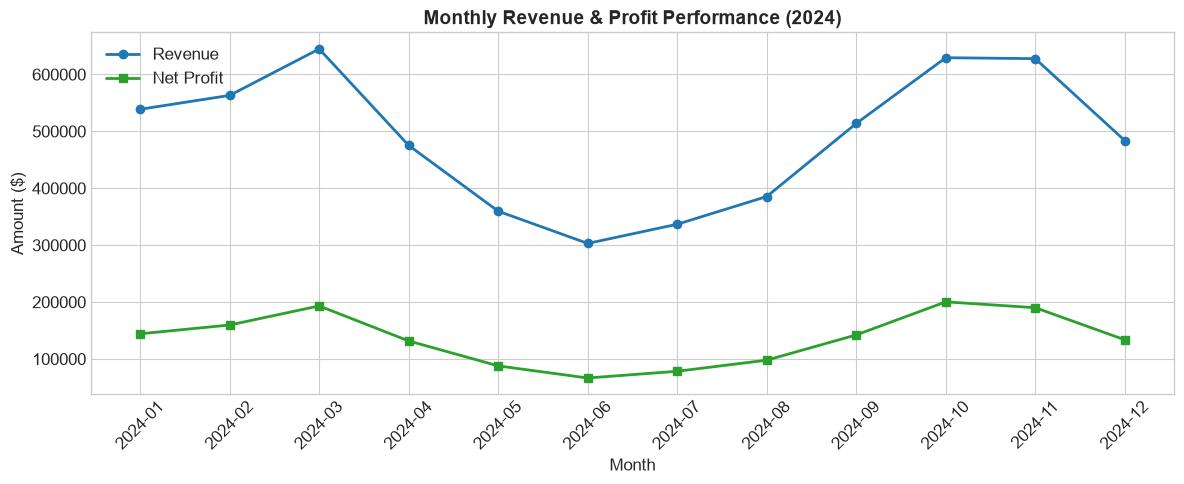

In [13]:
# Monthly Aggregation
monthly_df = df.groupby(df['Date'].dt.strftime('%Y-%m'))[['Revenue', 'Net_Profit']].sum().reset_index()
plt.figure(figsize=(12, 5))
plt.plot(monthly_df['Date'], monthly_df['Revenue'], marker='o', linewidth=2, label='Revenue', color='#1f77b4')
plt.plot(monthly_df['Date'], monthly_df['Net_Profit'], marker='s', linewidth=2, label='Net Profit', color='#2ca02c')
plt.title('Monthly Revenue & Profit Performance (2024)', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Amount ($)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

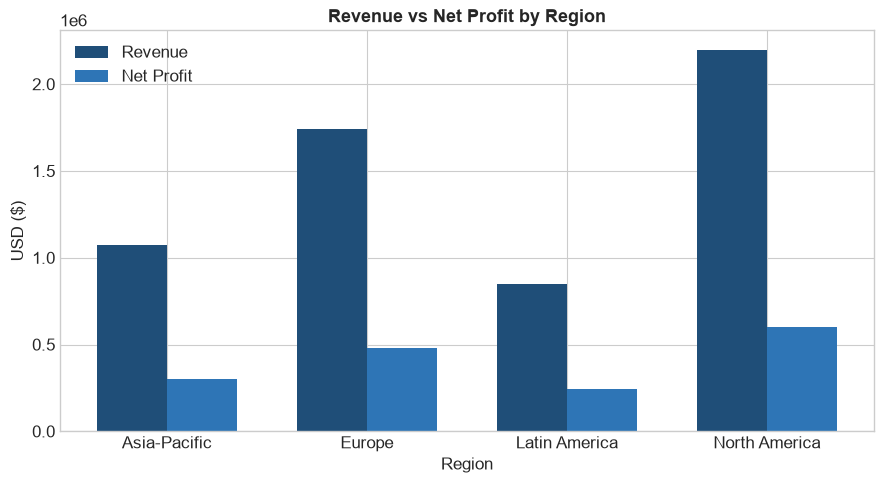

In [14]:
plt.figure(figsize=(9, 5))
x = np.arange(len(regional_summary['Region']))
width = 0.35

plt.bar(x - width/2, regional_summary['Revenue'], width, label='Revenue', color='#1F4E78')
plt.bar(x + width/2, regional_summary['Net_Profit'], width, label='Net Profit', color='#2E75B6')
plt.xlabel('Region')
plt.ylabel('USD ($)')
plt.title('Revenue vs Net Profit by Region', fontsize=13, fontweight='bold')
plt.xticks(x, regional_summary['Region'])
plt.legend()
plt.tight_layout()
plt.show()

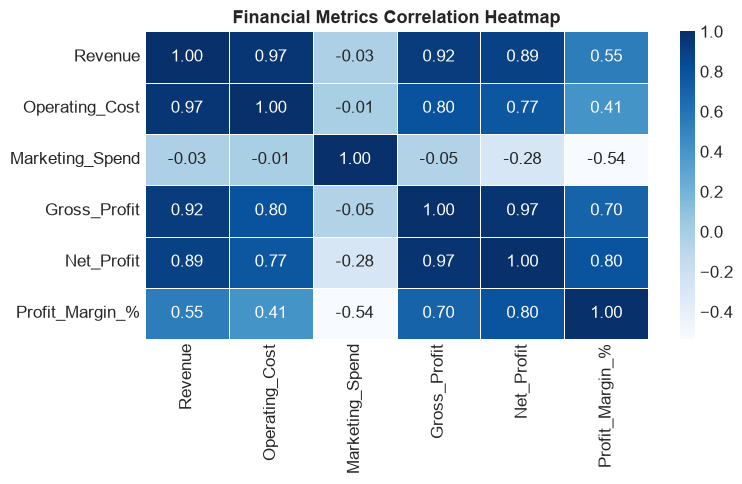

In [15]:
plt.figure(figsize=(8, 5))
numeric_cols = ['Revenue', 'Operating_Cost', 'Marketing_Spend', 'Gross_Profit', 'Net_Profit', 'Profit_Margin_%']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Financial Metrics Correlation Heatmap', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\acowe\AppData\Local\Temp\ipykernel_13704\3290089087.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Department', y='Profit_Margin_%', palette='Set2')


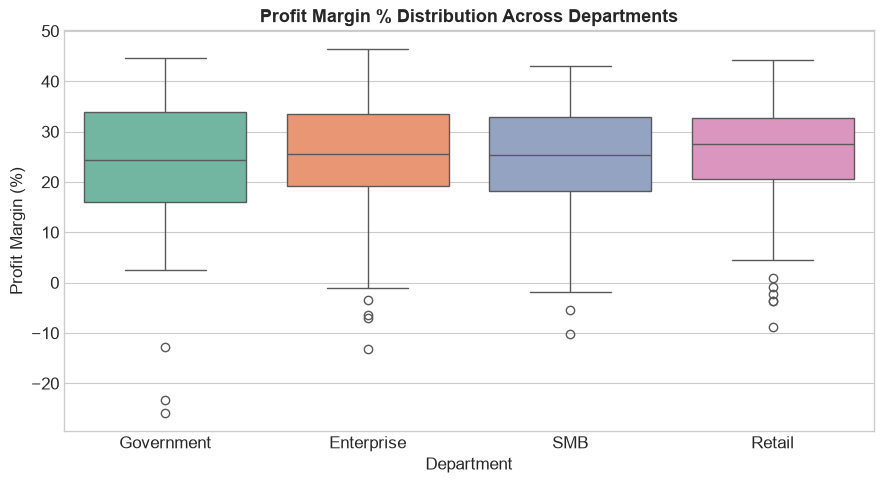

In [16]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Department', y='Profit_Margin_%', palette='Set2')

plt.title('Profit Margin % Distribution Across Departments', fontsize=13, fontweight='bold')
plt.xlabel('Department')
plt.ylabel('Profit Margin (%)')
plt.tight_layout()
plt.show()

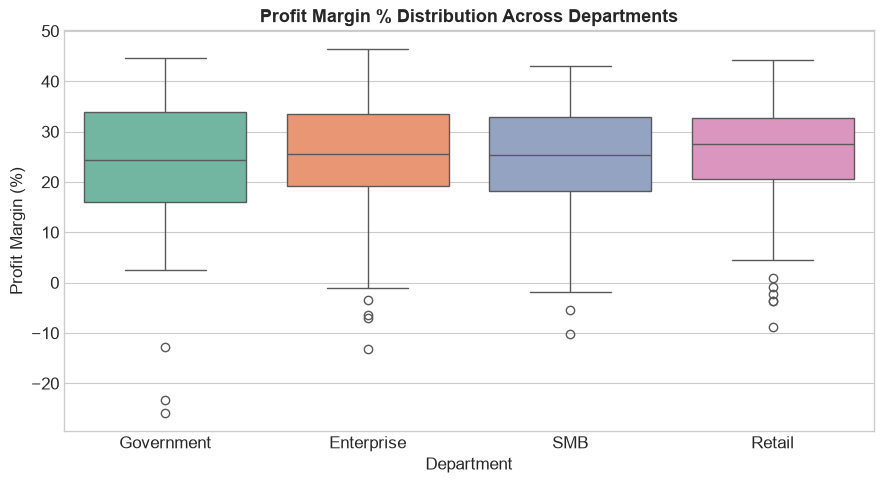

In [17]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Department', y='Profit_Margin_%',hue='Department', palette='Set2', legend=False)

plt.title('Profit Margin % Distribution Across Departments', fontsize=13, fontweight='bold')
plt.xlabel('Department')
plt.ylabel('Profit Margin (%)')
plt.tight_layout()
plt.show()